In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_line_colors=config['cell_line_colors']

TEMPDIR = Path(config['TEMPDIR'])

In [2]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Specificty as Ternary Plot

In [3]:
feature = 'gene'
tab = pd.read_csv(f'../results/mageck/summaries/{feature}_TP6_pooled_screen_1_counts_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
tab = tab.drop('sgRNA', axis=1)
tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

In [19]:
feature = 'gene'  # not checking transcript specificity, guides were not optimally designed for that
tab = pd.read_csv(f'../results/mageck/summaries/{feature}_TP6_pooled_screen_1_counts_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
tab = tab.drop('sgRNA', axis=1)
tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

# ternary plot for stab table
# take beta values
stab = tab.loc[:, (slice(None), 'beta')]

Y = -stab.values  # take negative values, as we want to plot the least unique genes in the center
Y = Y - np.mean(Y, axis=0) # center Y in the middle of the triangle
Y *= 2 # scaling, adjusts how centered the points are in the triangle
Y = np.exp(Y) / np.sum(np.exp(Y), axis=1)[:, None]  # apply softmax
Z = []
for a,b,c in Y:
    x = 0.5 * (2*b+c)/(a+b+c)
    y = np.sqrt(3)/2 * c/(a+b+c)
    Z.append([x,y])
Z = np.array(Z)

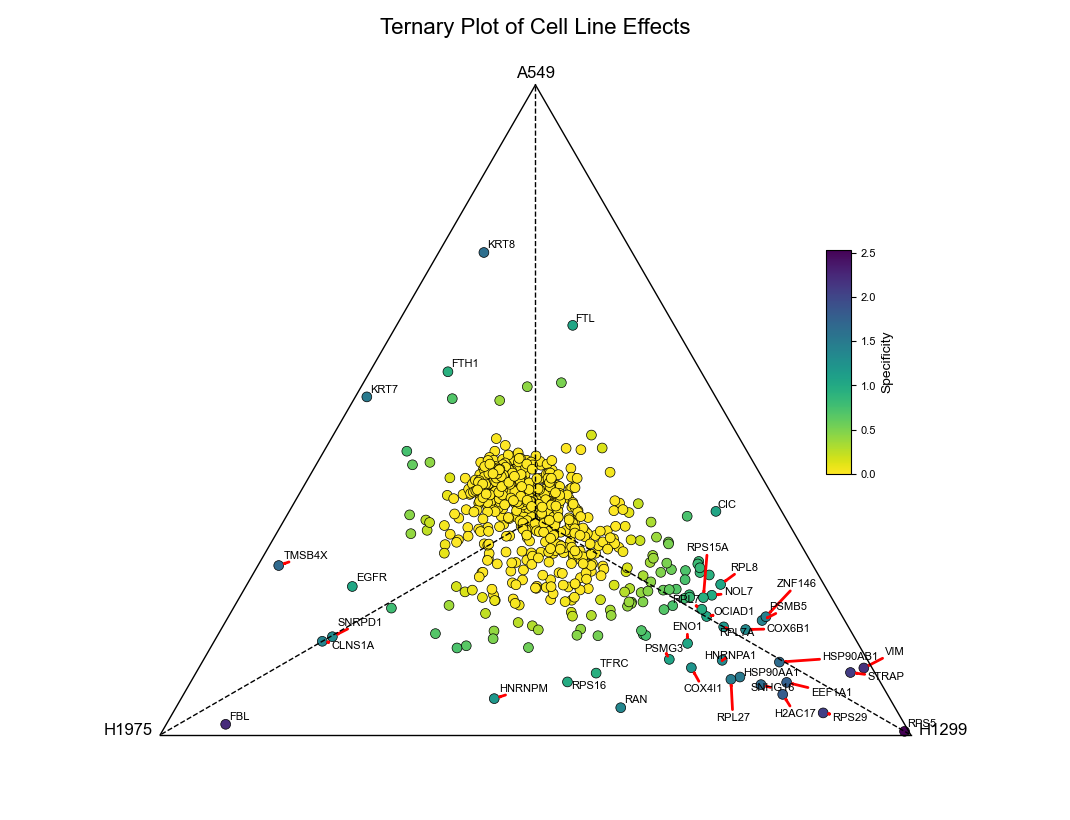

In [20]:
# Color: specificity
from scipy.stats import entropy, zscore
c = -zscore(entropy(Y, axis=1))
c = np.clip(c, 0, None)
c = np.log1p(c)

# plot ternary plot
width = 12
fig, ax = pl.subplots(figsize=(width+3, width*np.sqrt(3)/2), frameon=False)
ax.set_aspect('equal')
ax.set_axis_off()
scat = pl.scatter(Z[:,0], Z[:,1], c=c, cmap="viridis_r", s=50, edgecolor='k', linewidth=0.5)

import matplotlib.patheffects as PathEffects
mask = c > np.percentile(c, 95)
texts = []
for i, txt in enumerate(stab.index):
    if mask[i]:
        txt = ax.annotate(txt, (Z[i,0], Z[i,1]), fontsize=8)
        # txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground='white')])
        texts.append(txt)


# add triangle axes
pl.plot([0, 0.5], [0, np.sqrt(3)/2], 'k-', lw=1)
pl.plot([0.5, 1], [np.sqrt(3)/2, 0], 'k-', lw=1)
pl.plot([0, 1], [0, 0], 'k-', lw=1)

# add axes from the centroid to the edges of the triangle
centroid = [0.5, np.sqrt(3)/6]
pl.plot([centroid[0], 0], [centroid[1], 0], 'k--', lw=1)
pl.plot([centroid[0], 1], [centroid[1], 0], 'k--', lw=1)
pl.plot([centroid[0], 0.5], [centroid[1], np.sqrt(3)/2], 'k--', lw=1)

# add axes labels to the edges of the triangle
pl.text(-0.01, 0, 'H1975', fontsize=12, ha='right')
pl.text(1.01, 0, 'H1299', fontsize=12)
pl.text(0.5, np.sqrt(3)/2+0.01, 'A549', fontsize=12, ha='center')

# increase window size
pl.xlim(-0.2, 1.2)
pl.ylim(-0.1, np.sqrt(3)/2+0.1)

pl.title('Ternary Plot of Cell Line Effects', y=0.96, fontsize=16)
from adjustText import adjust_text
adjust_text(texts, expand=(1.2, 2), # expand text bounding boxes by 1.2 fold in x direction and 2 fold in y direction
            arrowprops=dict(arrowstyle="->", color='r', lw=2))

# Add internal colorbar without changing plot size
# Use inset_axes to place it inside the triangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
cb_ax = inset_axes(ax,
                   width="3%",  # Width of colorbar
                   height="40%",  # Height of colorbar
                   loc='upper right',
                   bbox_to_anchor=(0, 0, 0.8, 0.7),
                   bbox_transform=ax.transAxes,
                   borderpad=0,
                   )

cbar = pl.colorbar(scat, cax=cb_ax, label='Specificity')
cbar.ax.tick_params(labelsize=8)


pl.savefig(f'../results/mageck/{feature}_linespecificity_ternary_plot.pdf')#, bbox_inches='tight')
pl.show()

In [21]:
# Save the specificity table
for feature in ['gene', 'transcript']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_TP6_pooled_screen_1_counts_mageck_mle.gene_summary.txt', sep='\t', index_col=0)
    tab = tab.drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

    # ternary plot for stab table
    # take beta values
    stab = tab.loc[:, (slice(None), 'beta')]
    Y = -stab.values
    spec = pd.DataFrame(np.exp(Y) / np.sum(np.exp(Y), axis=1)[:, None])
    spec.columns = stab.columns
    spec.index = stab.index
    spec.to_csv(f'../results/mageck/{feature}_linespecificity.csv')

# Each TP with BAGEL essentials

In [7]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

In [8]:
# THIS IS ONLY TP6!
gene_cdf = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])
gene_cdf = gene_cdf[gene_cdf.index!='NT_Control']  # remove control
final_gene_list = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
gene_cdf['is_final'] = gene_cdf.index.isin(final_gene_list.index)
gene_cdf['essentiality'] = annotate_essentiality(gene_cdf.index)

In [29]:
counts = 'counts_filtered'
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

In [30]:
tab.head()

TP1                                                           \
cell_line    H1975                                                            
variable      beta        z   p-value       fdr  wald-p-value      wald-fdr   
Gene                                                                          
RPL10     -0.97809  -5.6330  0.000000  0.000000  1.771200e-08  7.647600e-07   
RAN       -1.05340 -13.7480  0.000000  0.000000  5.256100e-43  3.858000e-40   
ACTG1     -0.62033  -4.5716  0.000000  0.000000  4.840500e-06  1.015100e-04   
RPL14     -0.64354  -4.9894  0.000000  0.000000  6.055600e-07  1.852000e-05   
CCT8      -0.19131  -2.0709  0.001362  0.008929  3.836900e-02  8.057500e-02   

                                          ...     TP6                      \
cell_line    H1299                        ...   H1299                       
variable      beta        z p-value  fdr  ... p-value  fdr   wald-p-value   
Gene                                      ...                               
RPL10     -1.05690  -6.0827     0.0  0.0  ...     0.0  0.0   2.550900e-29   
RAN       -1.14570 -14.9080     0.0  0.0  ...     0.0  0.0  5.237400e-130   
ACTG1     -0.95358  -7.0218     0.0  0.0  ...     0.0  0.0   5.511500e-32   
RPL14     -0.89348  -6.9216     0.0  0.0  ...     0.0  0.0   7.286300e-28   
CCT8      -0.26908  -2.9123     0.0  0.0  ...     0.0  0.0   2.866500e-14   

                                                                      \
cell_line                   A549                                       
variable        wald-fdr    beta        z p-value  fdr  wald-p-value   
Gene                                                                   
RPL10       5.060400e-28 -2.0504  -6.6524     0.0  0.0  2.884100e-11   
RAN        3.844300e-127 -1.6820 -12.4630     0.0  0.0  1.190800e-35   
ACTG1       1.305000e-30 -2.1268  -8.2942     0.0  0.0  1.093100e-16   
RPL14       1.273400e-26 -2.4001  -9.3815     0.0  0.0  6.501800e-21   
CCT8        1.631000e-13 -1.6865  -6.2868     0.0  0.0  3.241600e-10   

                         
cell_line                
variable       wald-fdr  
Gene                     
RPL10      4.704300e-10  
RAN        8.740500e-33  
ACTG1      3.820600e-15  
RPL14      5.965400e-19  
CCT8       4.665300e-09  

[5 rows x 108 columns]

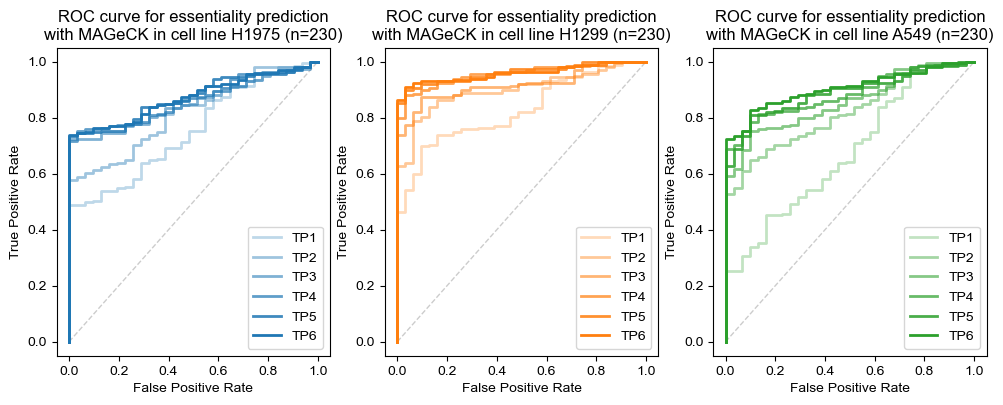

In [32]:
fig, axs = pl.subplots(1, 3, figsize=(12, 4), sharey=False)
for cell_line, ax in zip(cell_line_dict.values(), axs):
    for timepoint in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
        i = int(timepoint[-1])
        # get the data
        gene_cdf = tab.loc[:, (timepoint, cell_line, 'beta')].to_frame()
        gene_cdf.columns = ['beta']
        # get the essentiality
        gene_cdf['essentiality'] = annotate_essentiality(gene_cdf.index)
        # get the essentiality known
        essentiality_known = gene_cdf.essentiality != 'unknown'
        fpr, tpr, thresholds = roc_curve(gene_cdf.essentiality[essentiality_known] == 'essential', -gene_cdf.loc[essentiality_known, 'beta'])
        ax.plot(fpr, tpr, linewidth=2, color=cell_line_colors[cell_line], label=timepoint, alpha=(i+1)/7)
    ax.legend()
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC curve for essentiality prediction\nwith MAGeCK in cell line {cell_line} (n={int(sum(essentiality_known))})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, zorder=-1, alpha=0.4)
pl.savefig(f'../results/mageck/MAGECK_essential_roc_curves_over_time.pdf', bbox_inches='tight')
pl.show()

# TP1 vs TP5/6: early responders

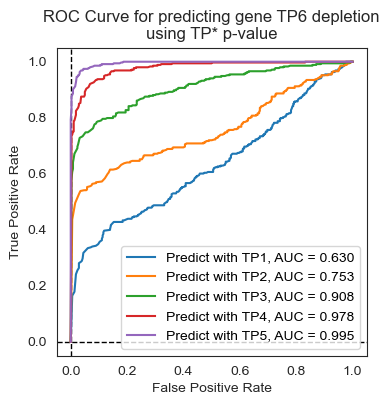

In [4]:
# Get data
feature = 'gene'
counts = 'counts_filtered'
tabs = {}
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

# Compare test results for TP1 and TP6 per line
# key = 'beta'
# with sns.axes_style('whitegrid'):
#     fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
# for cell_line, ax in zip(cell_line_dict.values(), axs):
#     stab = tab.loc[:, (slice(None), cell_line, slice(None))]
#     stab.columns = stab.columns.droplevel(1)
#     stab[('TP1', 'significant')] = (stab[('TP1', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
#     stab['significant'] = ['both' if x[0] and x[1] else 'TP1' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP1', 'significant')], stab[('TP6', 'significant')])]
    
#     sns.scatterplot(data=stab, x=('TP1', key), y=('TP6', key), hue='significant', s=20, ax=ax)
#     ax.set_xlabel(f'MAGeCK {key} for TP1')
#     ax.set_ylabel(f'MAGeCK {key} for TP6')
#     # plot diagonal line using min and max values of key
#     min_ = stab.loc[:, (slice(None), key)].min().max()
#     max_ = stab.loc[:, (slice(None), key)].max().max()
#     ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
#     ax.legend(title='Significant in')
#     ax.set_title(f'MAGeCK {key} values for TP1 and TP6 in {cell_line}', fontsize=16)
# pl.show()

# ROC curve for TP6 p-value using TP1 p-value
with sns.axes_style('white'):
    fig, ax = pl.subplots(figsize=(4,4)) 
from sklearn.metrics import roc_curve, roc_auc_score
stab = tab.loc[:, (slice(None), 'H1975', slice(None))]
stab.columns = stab.columns.droplevel(1)
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5']:
    fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[(key, 'p-value')])
    pl.plot(fpr, tpr, label=f'Predict with {key}, AUC = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.axhline(0, color='k', lw=1, ls='--', zorder=-1)
ax.axvline(0, color='k', lw=1, ls='--', zorder=-1)
ax.legend()
pl.title(f'ROC Curve for predicting {feature} TP6 depletion\nusing TP* p-value')
pl.savefig(f'../results/mageck/{feature}_ROC_curve_times.pdf', bbox_inches='tight')
pl.show()

# Summarize line-wise top early responder
# An early responder is a target that is significant at TP6 and has high beta value at TP1
early_responder = {}
for cell_line in cell_line_dict.values():
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab = stab[(stab[('TP6', 'fdr')] < 0.05) & (stab[('TP6', 'beta')] < 0) & (stab[('TP1', 'beta')] < 0) & (stab[('TP1', 'fdr')]<0.05)]
    stab = stab.sort_values(('TP1', 'beta'), ascending=True)
    early_responder[cell_line] = stab.index

# Save early responder table
max_length = max([len(x) for x in early_responder.values()])
# append None to shorter lists
for cell_line in early_responder:
    early_responder[cell_line] = list(early_responder[cell_line]) + [None] * (max_length - len(early_responder[cell_line]))
# Convert this dict into a DataFrame
early_responder_df = pd.DataFrame(early_responder)
early_responder_df.to_csv(f'../results/tables/{feature}_early_responders.csv')

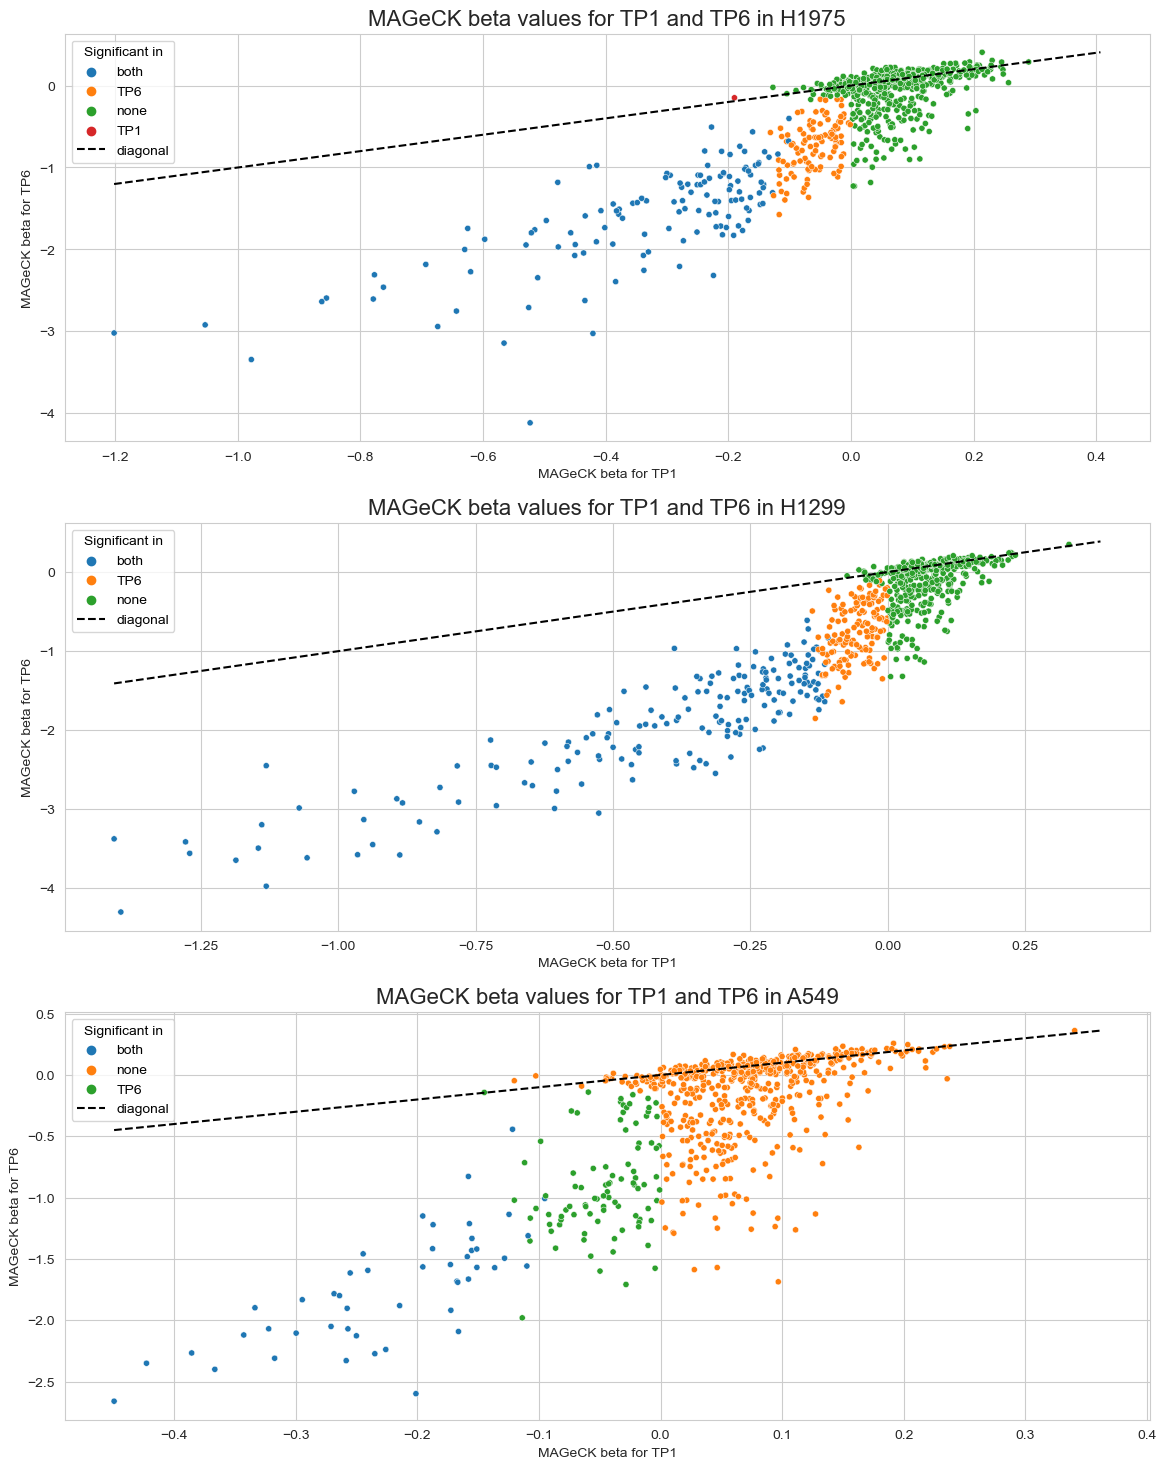

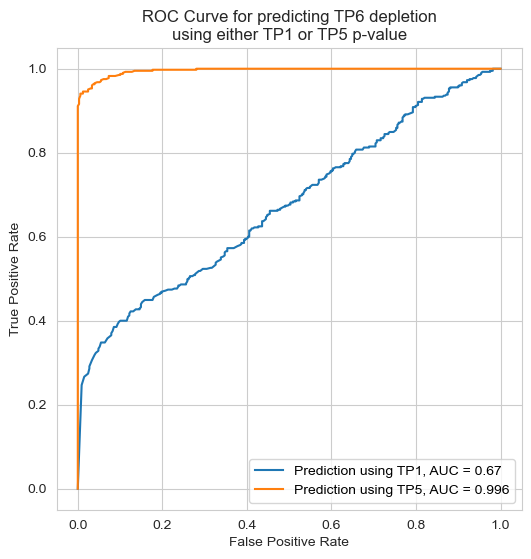

In [62]:
# Get data
feature = 'gene'
tabs = {}
for key in ['TP1', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/{feature}_{key}_pooled_screen_1_counts_filtered_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

# Compare test results for TP1 and TP6 per line
key = 'beta'
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
for cell_line, ax in zip(cell_line_dict.values(), axs):
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab[('TP1', 'significant')] = (stab[('TP1', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
    stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP1', 'beta')] < 0)
    stab['significant'] = ['both' if x[0] and x[1] else 'TP1' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP1', 'significant')], stab[('TP6', 'significant')])]
    
    sns.scatterplot(data=stab, x=('TP1', key), y=('TP6', key), hue='significant', s=20, ax=ax)
    ax.set_xlabel(f'MAGeCK {key} for TP1')
    ax.set_ylabel(f'MAGeCK {key} for TP6')
    # plot diagonal line using min and max values of key
    min_ = stab.loc[:, (slice(None), key)].min().max()
    max_ = stab.loc[:, (slice(None), key)].max().max()
    ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
    ax.legend(title='Significant in')
    ax.set_title(f'MAGeCK {key} values for TP1 and TP6 in {cell_line}', fontsize=16)
pl.show()

# ROC curve for TP6 p-value using TP1 p-value
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,6)) 
from sklearn.metrics import roc_curve, roc_auc_score
stab = tab.loc[:, (slice(None), 'H1975', slice(None))]
stab.columns = stab.columns.droplevel(1)
fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[('TP1', 'p-value')])
auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[('TP1', 'p-value')])
pl.plot(fpr, tpr, label=f'Prediction using TP1, AUC = {auc:.2f}')
fpr, tpr, _ = roc_curve(stab[('TP6', 'fdr')]<0.05, -stab[('TP5', 'p-value')])
auc = roc_auc_score(stab[('TP6', 'fdr')]<0.05, -stab[('TP5', 'p-value')])
pl.plot(fpr, tpr, label=f'Prediction using TP5, AUC = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
pl.title(f'ROC Curve for predicting TP6 depletion\nusing either TP1 or TP5 p-value')
pl.show()

# Summarize line-wise top early responder
# An early responder is a target that is significant at TP6 and has high beta value at TP1
early_responder = {}
for cell_line in cell_line_dict.values():
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab = stab[(stab[('TP6', 'fdr')] < 0.05) & (stab[('TP6', 'beta')] < 0) & (stab[('TP1', 'beta')] < 0) & (stab[('TP1', 'fdr')]<0.05)]
    stab = stab.sort_values(('TP1', 'beta'), ascending=True)
    early_responder[cell_line] = stab.index

# Save early responder table
max_length = max([len(x) for x in early_responder.values()])
# append None to shorter lists
for cell_line in early_responder:
    early_responder[cell_line] = list(early_responder[cell_line]) + [None] * (max_length - len(early_responder[cell_line]))
# Convert this dict into a DataFrame
early_responder_df = pd.DataFrame(early_responder)
early_responder_df.to_csv(f'../results/tables/{feature}_early_responders.csv')

# TP5 vs TP6: how different? Can we pool em?

In [73]:
# Get data
feature = 'transcript'
counts = 'counts_filtered'#
tabs = {}
for key in ['TP1', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

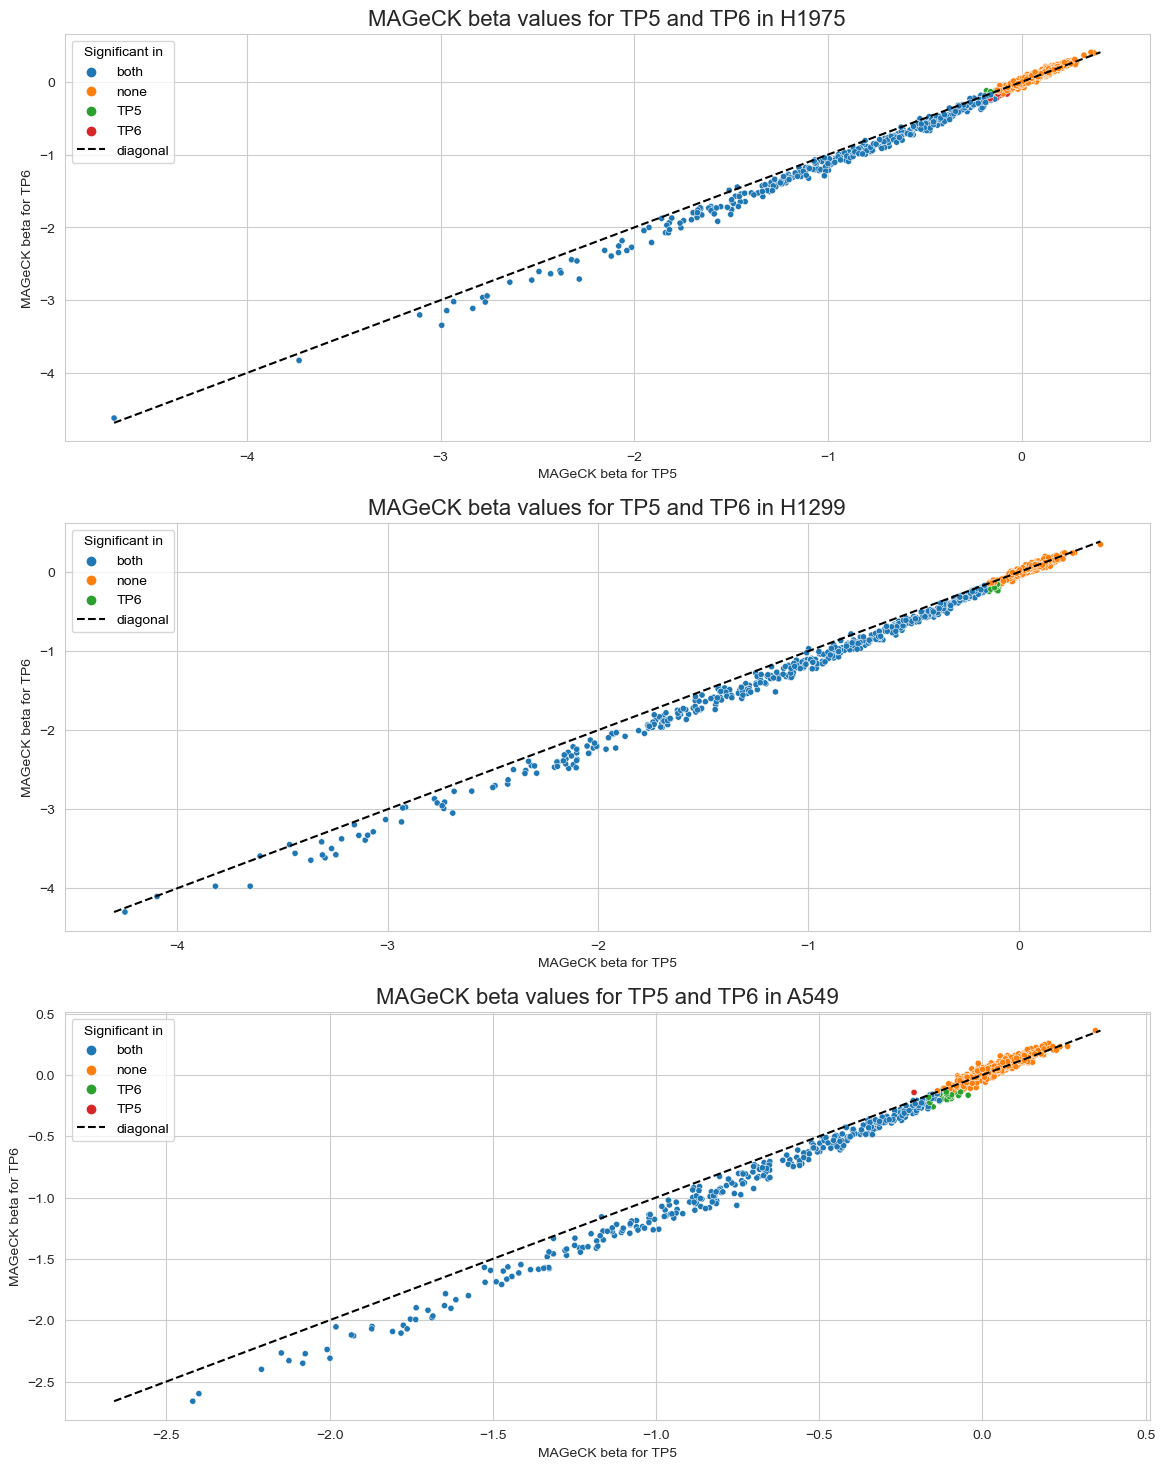

In [75]:
# Compare test results for TP1 and TP6 per line
key = 'beta'
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(3, 1, figsize=(14,6*3))
for cell_line, ax in zip(cell_line_dict.values(), axs):
    stab = tab.loc[:, (slice(None), cell_line, slice(None))]
    stab.columns = stab.columns.droplevel(1)
    stab[('TP5', 'significant')] = (stab[('TP5', 'p-value')] < 0.05) & (stab[('TP5', 'beta')] < 0)
    stab[('TP6', 'significant')] = (stab[('TP6', 'p-value')] < 0.05) & (stab[('TP6', 'beta')] < 0)
    stab['significant'] = ['both' if x[0] and x[1] else 'TP5' if x[0] else 'TP6' if x[1] else 'none' for x in zip(stab[('TP5', 'significant')], stab[('TP6', 'significant')])]
    
    sns.scatterplot(data=stab, x=('TP5', key), y=('TP6', key), hue='significant', s=20, ax=ax)
    ax.set_xlabel(f'MAGeCK {key} for TP5')
    ax.set_ylabel(f'MAGeCK {key} for TP6')
    # plot diagonal line using min and max values of key
    min_ = stab.loc[:, (slice(None), key)].min().min()
    max_ = stab.loc[:, (slice(None), key)].max().max()
    ax.plot([min_, max_], [min_, max_], 'k--', label='diagonal')
    ax.legend(title='Significant in')
    ax.set_title(f'MAGeCK {key} values for TP5 and TP6 in {cell_line}', fontsize=16)
pl.show()

# For our follow-up targets, at which TP do they stop being hits?

In [3]:
follow_ups = pd.read_excel('../resources/Selected_genes_for_follow_up.xlsx', sheet_name='Final_list ', index_col=1)
follow_ups = follow_ups.iloc[:-3]  # last 3 not in the screen
follow_up_transcripts = list(follow_ups.index.unique())

In [4]:
# Get data
feature = 'transcript'
counts = 'counts'#
tabs = {}
for key in ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']:
    tab = pd.read_csv(f'../results/mageck/summaries/{feature}_{key}_pooled_screen_1_{counts}_mageck_mle.gene_summary.txt', sep='\t', index_col=0).drop('sgRNA', axis=1)
    tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])
    tabs[key] = tab
tab = pd.concat(tabs, axis=1)

In [5]:
tab

TP1                                                     \
cell_line           H1975                                                      
variable             beta        z   p-value      fdr wald-p-value  wald-fdr   
Gene                                                                           
ENST00000400385  0.077629  3.13600  0.061441  0.22180     0.001713  0.007661   
ENST00000442925  0.021012  0.78264  0.611230  0.78933     0.433840  0.542440   
ENST00000437930  0.080736  3.97510  0.044492  0.17872     0.000070  0.000820   
ENST00000331789 -0.484270 -3.92280  0.000000  0.00000     0.000088  0.000928   
ENST00000573283 -0.511210 -4.26680  0.000000  0.00000     0.000020  0.000328   
...                   ...      ...       ...      ...          ...       ...   
ENST00000343769 -0.012814 -0.46160  0.868640  0.94037     0.644370  0.718160   
ENST00000310597  0.006899  0.28554  0.837920  0.92191     0.775230  0.832560   
ENST00000254821 -0.013814 -0.51445  0.848520  0.92816     0.606940  0.687820   
ENST00000370920  0.058764  2.05300  0.229870  0.46567     0.040071  0.087765   
ENST00000255152  0.029261  1.17020  0.508470  0.71111     0.241920  0.348130   

                                                        ...       TP6  \
cell_line           H1299                               ...     H1299   
variable             beta        z   p-value       fdr  ...   p-value   
Gene                                                    ...             
ENST00000400385  0.102840  4.15450  0.002119  0.013986  ...  0.024364   
ENST00000442925  0.010864  0.40465  0.716100  0.834570  ...  0.396190   
ENST00000437930  0.049937  2.45860  0.120760  0.274700  ...  0.210810   
ENST00000331789 -0.663750 -5.37310  0.000000  0.000000  ...  0.000000   
ENST00000573283 -0.781270 -6.51700  0.000000  0.000000  ...  0.000000   
...                   ...      ...       ...       ...  ...       ...   
ENST00000343769  0.035493  1.27860  0.355930  0.558870  ...  0.028602   
ENST00000310597  0.062879  2.60260  0.116530  0.271390  ...  0.512710   
ENST00000254821 -0.076854 -2.86150  0.163140  0.338460  ...  0.000000   
ENST00000370920  0.019059  0.66570  0.585810  0.754430  ...  0.000000   
ENST00000255152  0.030729  1.22890  0.423730  0.619200  ...  0.281780   

                                                                          \
cell_line                                                  A549            
variable              fdr  wald-p-value      wald-fdr      beta        z   
Gene                                                                       
ENST00000400385  0.044061  6.727500e-03  1.275200e-02  0.131640  3.70710   
ENST00000442925  0.504720  2.400600e-01  3.173900e-01 -0.025792 -0.68877   
ENST00000437930  0.295690  8.969000e-02  1.359000e-01  0.043606  1.35440   
ENST00000331789  0.000000  4.351100e-17  6.223400e-16 -1.617400 -6.92880   
ENST00000573283  0.000000  7.662300e-27  2.679000e-25 -1.917100 -8.03960   
...                   ...           ...           ...       ...      ...   
ENST00000343769  0.050847  1.405100e-01  2.006600e-01  0.045906  0.55079   
ENST00000310597  0.615780  3.041900e-01  3.864800e-01  0.034272  0.98606   
ENST00000254821  0.000000  6.093100e-10  3.324800e-09 -0.150950 -1.21610   
ENST00000370920  0.000000  2.416400e-05  6.669700e-05 -0.049744 -0.48443   
ENST00000255152  0.382180  1.430900e-01  2.037300e-01  0.053393  1.33910   

                                                                 
cell_line                                                        
variable          p-value       fdr  wald-p-value      wald-fdr  
Gene                                                             
ENST00000400385  0.000000  0.000000  2.096500e-04  1.206700e-03  
ENST00000442925  0.576270  0.686000  4.909700e-01  6.271600e-01  
ENST00000437930  0.283900  0.406060  1.756100e-01  3.047400e-01  
ENST00000331789  0.000000  0.000000  4.243000e-12  1.430500e-10  
ENST00000573283  0.000000  0.000000  9.016500e-16  5.006

In [6]:
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

avg_l2fc = l2fc.groupby(df.Transcript_ID).mean().loc[follow_up_transcripts, sample_names[3:]]

# Sample-level annotation
cell_line = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in avg_l2fc.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in avg_l2fc.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in avg_l2fc.columns})

avg_l2fc.columns = pd.MultiIndex.from_tuples(zip(cell_line, replicate, time_point), names=['cell_line', 'replicate', 'time_point'])
avg_l2fc = avg_l2fc.T.groupby(['cell_line', 'time_point']).mean().T

In [7]:
mask1 = (tab.loc[follow_up_transcripts, (slice(None), slice(None), 'fdr')] < 0.01).sort_index(axis=1, level=[1,0])
mask2 = (avg_l2fc < -0.5)

hit_tab = pd.DataFrame(mask1.values & mask2.values, columns=avg_l2fc.columns, index=avg_l2fc.index)

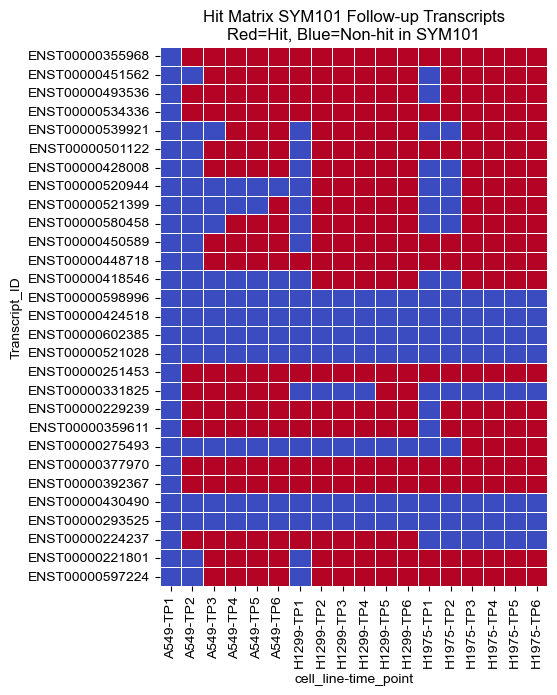

In [8]:
fig, ax = pl.subplots(figsize=(5, 7))
sns.heatmap(hit_tab, cmap='coolwarm', cbar=False, linewidths=0.5, linecolor='white')
pl.title('Hit Matrix SYM101 Follow-up Transcripts\nRed=Hit, Blue=Non-hit in SYM101')
pl.show()

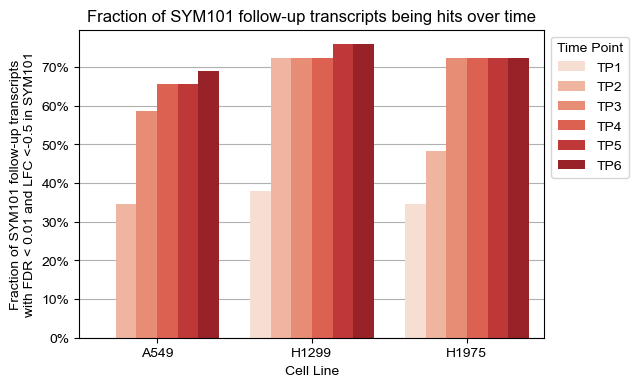

In [9]:
dat = hit_tab.sum(0).reset_index()
dat[0] = dat[0] / len(follow_up_transcripts)
dat['time_point_int'] = dat['time_point'].map({'TP1': 1, 'TP2': 2, 'TP3': 3, 'TP4': 4, 'TP5': 5, 'TP6': 6})
fig, ax = pl.subplots(figsize=(6,4))
sns.barplot(data=dat, x='cell_line', y=0, hue='time_point', palette='Reds', ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1,1), title='Time Point')
# y axis to percentage
from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Fraction of SYM101 follow-up transcripts\nwith FDR < 0.01 and LFC <-0.5 in SYM101')
ax.set_axisbelow(True)
ax.grid(axis='y')
ax.set_title('Fraction of SYM101 follow-up transcripts being hits over time')
ax.set_xlabel('Cell Line')
pl.savefig(f'../results/mageck/SYM101_followup_transcripts_hits.pdf', bbox_inches='tight')
pl.show()